# 다른 백본 파인튜닝 — 웨이퍼 결함 패턴 8클래스 분류

`resnet18_finetune.ipynb`와 **데이터 전처리 / split(SEED=1414) / 증강 / 손실 / 학습 루프 / 평가를 완전히 동일**하게 두고 백본만 교체합니다.
마지막에 저장된 `outputs/resnet18_best.pth`를 같은 test 세트로 평가해 나란히 비교합니다.

`MODEL_NAME`으로 선택:

| MODEL_NAME | 파라미터 | 특징 |
|---|---|---|
| `efficientnet_b0` (기본) | 4.0M | depthwise conv + SE, 적은 파라미터로 ResNet보다 높은 ImageNet 정확도 |
| `convnext_tiny` | 27.8M | 7x7 depthwise, LayerNorm — 현대적인 순수 CNN |
| `resnet50` | 23.5M | ResNet18의 깊은 버전 |


In [1]:
import os, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from torchvision import models

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, confusion_matrix, accuracy_score

SEED = 1414
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

CLASS_NAMES = ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Random', 'Scratch', 'Near-full']
NUM_CLASSES = len(CLASS_NAMES)

MODEL_NAME = "efficientnet_b0"   # "efficientnet_b0" | "convnext_tiny" | "resnet50"

IMG_SIZE   = 96      # 세 백본 모두 1/32로 줄이므로 96 -> 3x3 feature map
BATCH_SIZE = 128
EPOCHS     = 30
PATIENCE   = 7       # val macro F1이 이 epoch 수만큼 안 오르면 중단
LR         = 1e-3    # head
BACKBONE_LR = 3e-4   # 사전학습 backbone은 더 작게
WEIGHT_DECAY = 1e-4
OUT_PATH = f"outputs/{MODEL_NAME}_best.pth"
os.makedirs("outputs", exist_ok=True)

device: cuda NVIDIA GeForce RTX 2060 SUPER


## 1. 데이터 로드 & 전처리 (한 번만 리사이즈해서 메모리에 올림)

In [2]:
df = pd.read_pickle("../wb_withpattern.pkl")
df = df[['waferMap', 'failureNum']].reset_index(drop=True)
df['failureNum'] = df['failureNum'].astype(int)
print(df.shape)
print(df['failureNum'].value_counts().sort_index().rename(index=dict(enumerate(CLASS_NAMES))))

(25519, 2)
Center       4294
Donut         555
Edge-Loc     5189
Edge-Ring    9680
Loc          3593
Random        866
Scratch      1193
Near-full     149
Name: failureNum, dtype: int64


In [3]:
LUT = np.array([0, 128, 255], dtype=np.uint8)   # 0: 웨이퍼 밖, 1: 정상 die, 2: 불량 die

def preprocess(wmap, size=IMG_SIZE):
    img = LUT[np.clip(np.asarray(wmap, dtype=np.uint8), 0, 2)]
    return np.asarray(Image.fromarray(img).resize((size, size), Image.NEAREST))

t0 = time.time()
X = np.stack([preprocess(m) for m in tqdm(df['waferMap'], desc="resize")])   # (N, H, W) uint8
y = df['failureNum'].values
print(X.shape, X.dtype, f"{time.time()-t0:.1f}s")

resize:   0%|          | 0/25519 [00:00<?, ?it/s]

(25519, 96, 96) uint8 2.4s


In [4]:
# train / val / test = 72 / 8 / 20 (stratified)
idx = np.arange(len(y))
idx_trval, idx_test = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
idx_train, idx_val  = train_test_split(idx_trval, test_size=0.1, stratify=y[idx_trval], random_state=SEED)
print(len(idx_train), len(idx_val), len(idx_test))

def make_loader(ids, shuffle):
    ds = TensorDataset(torch.from_numpy(X[ids]), torch.from_numpy(y[ids]).long())
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0, pin_memory=True)

train_loader = make_loader(idx_train, True)
val_loader   = make_loader(idx_val, False)
test_loader  = make_loader(idx_test, False)

18373 2042 5104


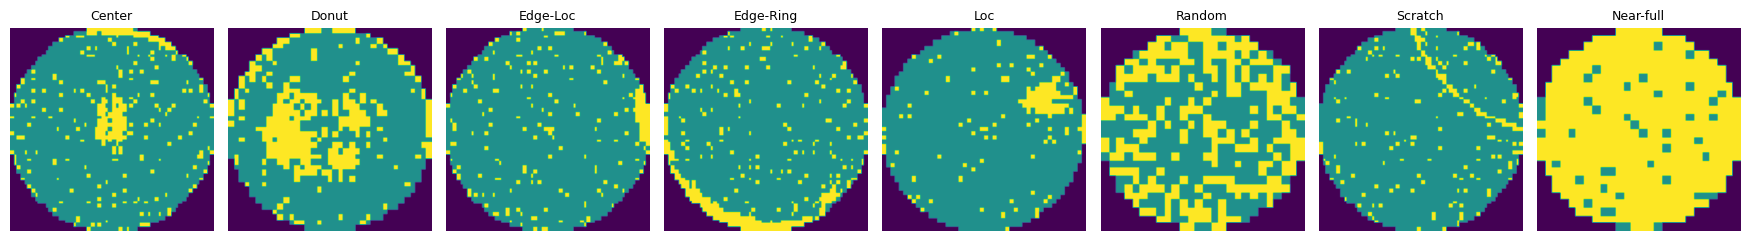

In [5]:
# 클래스별 샘플 확인
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(2.2 * NUM_CLASSES, 2.4))
for c, ax in enumerate(axes):
    i = np.where(y == c)[0][0]
    ax.imshow(X[i], cmap='viridis'); ax.set_title(CLASS_NAMES[c], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 2. GPU 배치 전처리 / 증강

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def to_input(xb):
    # uint8 (B,H,W) -> 정규화된 float (B,3,H,W)
    x = xb.to(DEVICE, non_blocking=True).float().div_(255.).unsqueeze(1).expand(-1, 3, -1, -1)
    return (x - MEAN) / STD

def dihedral(x, k, flip):
    x = torch.rot90(x, k, dims=(2, 3))
    return torch.flip(x, dims=(3,)) if flip else x

def augment(x):
    # 배치 안 샘플마다 8가지(회전 4 x 반전 2) 중 하나를 랜덤 적용
    out = torch.empty_like(x)
    choice = torch.randint(0, 8, (x.size(0),), device=x.device)
    for t in range(8):
        m = choice == t
        if m.any():
            out[m] = dihedral(x[m], t % 4, t >= 4)
    return out

## 3. 모델: ImageNet 사전학습 백본 + 새 분류 head

In [7]:
def build_model(name=MODEL_NAME):
    if name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, NUM_CLASSES))
        head = m.classifier
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        m.classifier[2] = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[2].in_features, NUM_CLASSES))
        head = m.classifier[2]
    elif name == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, NUM_CLASSES))
        head = m.fc
    elif name == "resnet18":   # 비교용 (기존 노트북과 동일한 구조, 가중치는 체크포인트에서 로드)
        m = models.resnet18(weights=None)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, NUM_CLASSES))
        head = m.fc
    else:
        raise ValueError(name)
    return m.to(DEVICE), head

model, head = build_model()
print("model:", MODEL_NAME)
print(f"params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

# 클래스 가중치: 역빈도의 제곱근 (Near-full 149장 vs Edge-Ring 9680장)
counts = np.bincount(y[idx_train], minlength=NUM_CLASSES)
w = (counts.sum() / counts) ** 0.5
w = torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)
print("class weights:", dict(zip(CLASS_NAMES, w.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=w, label_smoothing=0.05)

head_params = list(head.parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": BACKBONE_LR},
    {"params": head_params, "lr": LR},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=[BACKBONE_LR, LR], epochs=EPOCHS,
    steps_per_epoch=len(train_loader), pct_start=0.15)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\hkh97/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth

  0%|          | 0.00/20.5M [00:00<?, ?B/s]
 23%|██▎       | 4.62M/20.5M [00:00<00:00, 47.5MB/s]
 52%|█████▏    | 10.6M/20.5M [00:00<00:00, 55.5MB/s]
 82%|████████▏ | 16.8M/20.5M [00:00<00:00, 57.8MB/s]
100%|██████████| 20.5M/20.5M [00:00<00:00, 58.2MB/s]


model: efficientnet_b0
params: 4.02M
class weights: {'Center': 0.5, 'Donut': 1.39, 'Edge-Loc': 0.46, 'Edge-Ring': 0.33, 'Loc': 0.55, 'Random': 1.12, 'Scratch': 0.95, 'Near-full': 2.7}


## 4. 학습 (early stopping: val macro F1)

In [8]:
@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()
    probs, ys = [], []
    for xb, yb in loader:
        x = to_input(xb)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            if tta:
                p = sum(F.softmax(model(dihedral(x, k, f)), 1) for k in range(4) for f in (False, True)) / 8
            else:
                p = F.softmax(model(x), 1)
        probs.append(p.float().cpu()); ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

history = []
best_f1, best_state, bad = -1, None, 0
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, tot_loss, correct, n = time.time(), 0.0, 0, 0
    for xb, yb in train_loader:
        x, yb = augment(to_input(xb)), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
            logits = model(x)
            loss = criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update(); scheduler.step()
        tot_loss += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item(); n += yb.size(0)

    p_val, y_val = predict(model, val_loader)
    val_pred = p_val.argmax(1)
    val_acc, val_f1 = accuracy_score(y_val, val_pred), f1_score(y_val, val_pred, average='macro')
    history.append(dict(epoch=epoch, loss=tot_loss / n, train_acc=correct / n, val_acc=val_acc, val_f1=val_f1))

    flag = ""
    if val_f1 > best_f1:
        best_f1, best_state, bad, flag = val_f1, copy.deepcopy(model.state_dict()), 0, "  *best"
        torch.save(best_state, OUT_PATH)
    else:
        bad += 1
    print(f"[{epoch:2d}] loss={tot_loss/n:.4f} train_acc={correct/n:.4f} | "
          f"val_acc={val_acc:.4f} val_macroF1={val_f1:.4f} ({time.time()-t0:.0f}s){flag}")
    if bad >= PATIENCE:
        print(f"early stop (best val macro F1 = {best_f1:.4f})")
        break

model.load_state_dict(best_state)
hist = pd.DataFrame(history)

C:\Users\hkh97\anaconda3\envs\han\lib\site-packages\torch\optim\lr_scheduler.py:216: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


[ 1] loss=1.7965 train_acc=0.4747 | val_acc=0.6978 val_macroF1=0.6278 (18s)  *best
[ 2] loss=1.1043 train_acc=0.7589 | val_acc=0.8560 val_macroF1=0.8173 (12s)  *best
[ 3] loss=0.8042 train_acc=0.8751 | val_acc=0.9094 val_macroF1=0.8815 (12s)  *best
[ 4] loss=0.7152 train_acc=0.9099 | val_acc=0.9344 val_macroF1=0.9098 (13s)  *best
[ 5] loss=0.6724 train_acc=0.9248 | val_acc=0.9432 val_macroF1=0.9286 (12s)  *best
[ 6] loss=0.6425 train_acc=0.9360 | val_acc=0.9471 val_macroF1=0.9307 (11s)  *best
[ 7] loss=0.6209 train_acc=0.9412 | val_acc=0.9456 val_macroF1=0.9282 (11s)
[ 8] loss=0.6099 train_acc=0.9483 | val_acc=0.9407 val_macroF1=0.9154 (12s)
[ 9] loss=0.6003 train_acc=0.9512 | val_acc=0.9505 val_macroF1=0.9417 (12s)  *best
[10] loss=0.5874 train_acc=0.9525 | val_acc=0.9491 val_macroF1=0.9313 (11s)
[11] loss=0.5787 train_acc=0.9568 | val_acc=0.9471 val_macroF1=0.9259 (12s)
[12] loss=0.5699 train_acc=0.9617 | val_acc=0.9515 val_macroF1=0.9435 (11s)  *best
[13] loss=0.5639 train_acc=0.965

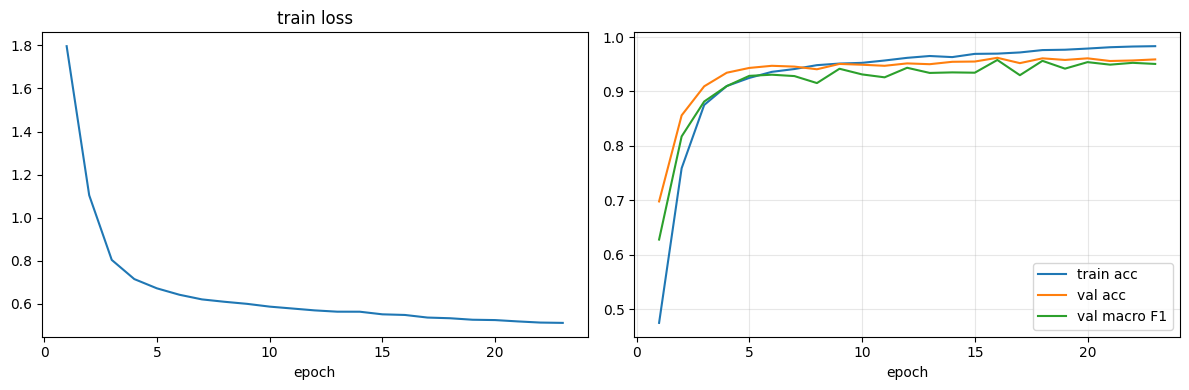

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoch, hist.loss); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist.epoch, hist.train_acc, label="train acc")
ax[1].plot(hist.epoch, hist.val_acc, label="val acc")
ax[1].plot(hist.epoch, hist.val_f1, label="val macro F1")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Test 평가 (best 체크포인트, TTA 유무 비교)

In [10]:
p_test, y_test = predict(model, test_loader, tta=False)
p_tta, _       = predict(model, test_loader, tta=True)
pred, pred_tta = p_test.argmax(1), p_tta.argmax(1)

summary = pd.DataFrame({
    "accuracy": [accuracy_score(y_test, pred), accuracy_score(y_test, pred_tta)],
    "macro F1": [f1_score(y_test, pred, average='macro'), f1_score(y_test, pred_tta, average='macro')],
}, index=[MODEL_NAME, MODEL_NAME + " + TTA"]).round(4)
print(summary, "\n")
print(f"[{MODEL_NAME} + TTA] test classification report")
print(classification_report(y_test, pred_tta, target_names=CLASS_NAMES, digits=4))

                       accuracy  macro F1
efficientnet_b0          0.9491    0.9349
efficientnet_b0 + TTA    0.9549    0.9430 

[efficientnet_b0 + TTA] test classification report
              precision    recall  f1-score   support

      Center     0.9658    0.9849    0.9752       859
       Donut     0.8852    0.9730    0.9270       111
    Edge-Loc     0.9502    0.9200    0.9349      1038
   Edge-Ring     0.9821    0.9928    0.9874      1936
         Loc     0.9142    0.8748    0.8941       719
      Random     0.9360    0.9306    0.9333       173
     Scratch     0.8784    0.9412    0.9087       238
   Near-full     1.0000    0.9667    0.9831        30

    accuracy                         0.9549      5104
   macro avg     0.9390    0.9480    0.9430      5104
weighted avg     0.9549    0.9549    0.9547      5104



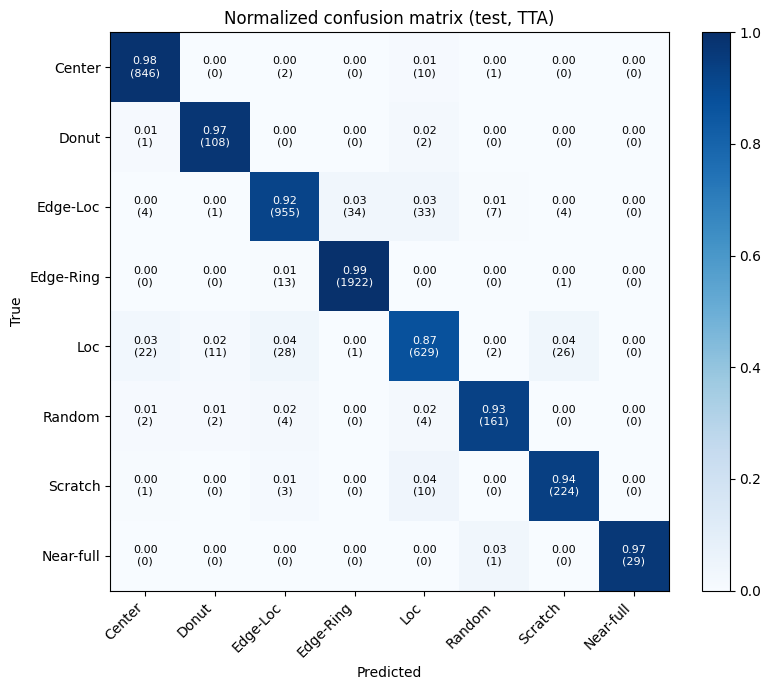

In [11]:
cm = confusion_matrix(y_test, pred_tta)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cmn[i,j]:.2f}\n({cm[i,j]})", ha='center', va='center', fontsize=8,
                color='white' if cmn[i, j] > .5 else 'black')
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Normalized confusion matrix (test, TTA)")
plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.show()

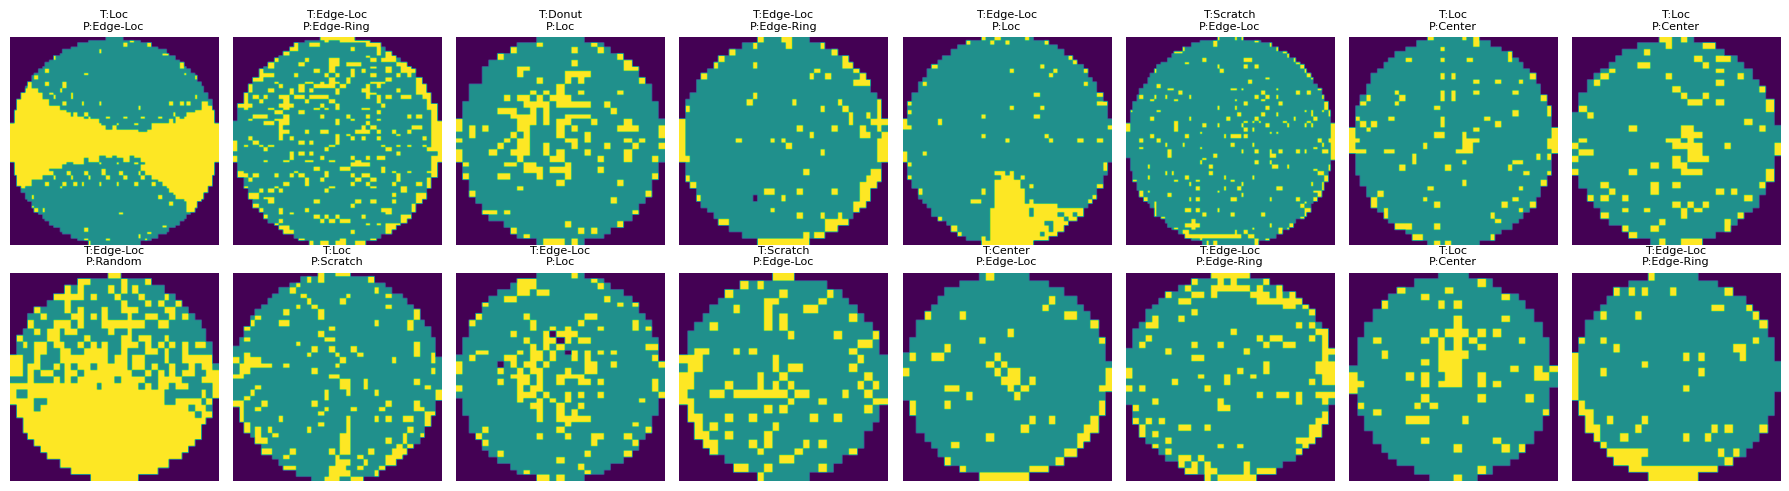

오분류 230 / 5104


In [12]:
# 틀린 예시 확인
wrong = np.where(pred_tta != y_test)[0]
show = wrong[:16]
fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for ax, k in zip(axes.ravel(), show):
    ax.imshow(X[idx_test[k]], cmap='viridis'); ax.axis('off')
    ax.set_title(f"T:{CLASS_NAMES[y_test[k]]}\nP:{CLASS_NAMES[pred_tta[k]]}", fontsize=8)
for ax in axes.ravel()[len(show):]: ax.axis('off')
plt.tight_layout(); plt.show()
print(f"오분류 {len(wrong)} / {len(y_test)}")

## 6. ResNet18 (기존 체크포인트)과 비교 — 같은 test 세트

In [13]:
RES18_PATH = "outputs/resnet18_best.pth"
rows = {f"{MODEL_NAME} + TTA": p_tta}
if os.path.exists(RES18_PATH):
    r18, _ = build_model("resnet18")
    r18.load_state_dict(torch.load(RES18_PATH, map_location=DEVICE))
    rows["resnet18 + TTA"], _ = predict(r18, test_loader, tta=True)
    del r18; torch.cuda.empty_cache()

cmp = pd.DataFrame({k: {"accuracy": accuracy_score(y_test, p.argmax(1)),
                        "macro F1": f1_score(y_test, p.argmax(1), average='macro')} for k, p in rows.items()}).T
per_cls = pd.DataFrame({k: f1_score(y_test, p.argmax(1), average=None) for k, p in rows.items()}, index=CLASS_NAMES).T
print(cmp.round(4), "\n")
print("클래스별 F1"); print(per_cls.round(3))


C:\Users\hkh97\AppData\Local\Temp\ipykernel_15176\2338417838.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  r18.load_state_dict(torch.load(RES18_PATH, map_location=DEVI

                       accuracy  macro F1
efficientnet_b0 + TTA    0.9549    0.9430
resnet18 + TTA           0.9557    0.9392 

클래스별 F1
                       Center  Donut  Edge-Loc  Edge-Ring    Loc  Random  \
efficientnet_b0 + TTA   0.975  0.927     0.935      0.987  0.894   0.933   
resnet18 + TTA          0.978  0.915     0.937      0.990  0.893   0.935   

                       Scratch  Near-full  
efficientnet_b0 + TTA    0.909      0.983  
resnet18 + TTA           0.898      0.968  
